In [47]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [48]:
import matplotlib.pyplot as plt
import numpy as np
import os
import glob
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [49]:


IMAGE_DIR = "/kaggle/input/datasets/pancisaigo/pkg-tp53-precursor-lesions/PKG - TP53-Precursor-Lesions/data"

image_paths = sorted(glob.glob(os.path.join(IMAGE_DIR, "*.tif")))

data = pd.DataFrame({
    "image_path": image_paths,
    "filename": [os.path.basename(p) for p in image_paths]
})

print(data.shape)
data.head()

(273, 2)


,image_path,filename
0,/kaggle/input/datasets/pancisaigo/pkg-tp53-pre...,OCP100_top_01_count20-30.tif
1,/kaggle/input/datasets/pancisaigo/pkg-tp53-pre...,OCP102_bottom_01_count50-60.tif
2,/kaggle/input/datasets/pancisaigo/pkg-tp53-pre...,OCP107_3_top_29_count90-100.tif
3,/kaggle/input/datasets/pancisaigo/pkg-tp53-pre...,OCP107_3_top_30_count80-90-100_Ki67_4x.tif
4,/kaggle/input/datasets/pancisaigo/pkg-tp53-pre...,OCP107_3_top_30_count80-90.tif


In [50]:
DEVICE = torch.device("cuda")
BATCH_SIZE = 64
LATENT_DIM = 32
RIESZ_S = 2.0
LR = 1e-3
EPOCHS = 100
HIDDEN_DIM = 400
IMAGE_SIZE = (64, 64)
IN_CHANNELS = 3
INPUT_DIM = IN_CHANNELS * IMAGE_SIZE[0] * IMAGE_SIZE[1]

In [51]:


class imageDataset(Dataset):
    def __init__(self, image_dir, transform=None, max_images=None):

        self.image_paths = glob.glob(os.path.join(image_dir, "*.tif"))
        self.image_paths.sort()  # 保证顺序稳定

        if max_images is not None:
            self.image_paths = self.image_paths[:max_images]

        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image


transform = transforms.Compose([
    transforms.CenterCrop(178),
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor()
])



dataset = imageDataset(IMAGE_DIR, transform=transform, max_images=10000)

data_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("Total number of images:", len(dataset))

Total number of images: 273


In [52]:
# --- 1. Definizione Modello Standard VAE ---
class StandardVAE(nn.Module):
    def __init__(self):
        super(StandardVAE, self).__init__()

        # Encoder
        self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)

        # Mu e log-varianza del VAE standard
        self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.fc_logvar = nn.Linear(HIDDEN_DIM, LATENT_DIM)

        # Decoder
        self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc3 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def encode(self, x):
        h = F.relu(self.fc1(x))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        if self.training:
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        else:
            return mu

    def decode(self, z):
        h = F.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x):
        x = x.view(x.size(0), -1)   # flatten
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, z, mu, logvar


# --- 2. Loss Function (ELBO) ---
def loss_function(recon_x, x, mu, logvar):
    x = x.view(x.size(0), -1)   # original image flatten to [B, INPUT_DIM]
    mse = F.mse_loss(recon_x, x, reduction='sum')
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return mse + kld


# --- 3. Training Loop ---
def train_standard_vae():
    print(f"Start Training Standard VAE on {DEVICE}...")

    model = StandardVAE().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    model.train()

    for epoch in range(EPOCHS):
        total_loss = 0

        for batch_idx, batch in enumerate(data_loader):
            data = batch.to(DEVICE)

            optimizer.zero_grad()

            recon, z, mu, logvar = model(data)
            loss = loss_function(recon, data, mu, logvar)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(data_loader.dataset)
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss (ELBO): {avg_loss:.4f}")

    print("Training completato.")
    return model


# --- Esecuzione ---
model_v = train_standard_vae()

Start Training Standard VAE on cuda...
Epoch 1/100 | Loss (ELBO): 1011.6268
Epoch 2/100 | Loss (ELBO): 365.2660
Epoch 3/100 | Loss (ELBO): 251.5549
Epoch 4/100 | Loss (ELBO): 234.0004
Epoch 5/100 | Loss (ELBO): 224.0028
Epoch 6/100 | Loss (ELBO): 225.1565
Epoch 7/100 | Loss (ELBO): 215.2518
Epoch 8/100 | Loss (ELBO): 218.1135
Epoch 9/100 | Loss (ELBO): 224.0879
Epoch 10/100 | Loss (ELBO): 215.3058
Epoch 11/100 | Loss (ELBO): 227.3868
Epoch 12/100 | Loss (ELBO): 218.1831
Epoch 13/100 | Loss (ELBO): 207.1805
Epoch 14/100 | Loss (ELBO): 203.7573
Epoch 15/100 | Loss (ELBO): 202.2419
Epoch 16/100 | Loss (ELBO): 204.7884
Epoch 17/100 | Loss (ELBO): 211.2662
Epoch 18/100 | Loss (ELBO): 211.7411
Epoch 19/100 | Loss (ELBO): 194.6227
Epoch 20/100 | Loss (ELBO): 195.1276
Epoch 21/100 | Loss (ELBO): 189.0801
Epoch 22/100 | Loss (ELBO): 187.9447
Epoch 23/100 | Loss (ELBO): 187.0358
Epoch 24/100 | Loss (ELBO): 192.2810
Epoch 25/100 | Loss (ELBO): 195.1796
Epoch 26/100 | Loss (ELBO): 190.7330
Epoch 2

In [53]:
# --- 1. Loss: Riesz s-kernel Energy ---
def riesz_energy_loss(z):
    # Se il batch contiene meno di 2 punti, non si può calcolare pdist
    if z.size(0) < 2:
        return torch.tensor(0.0, device=z.device)

    dists = torch.pdist(z, p=2)

    # Protezione numerica
    dists = torch.clamp(dists, min=1e-6)

    energy = 1.0 / dists.pow(RIESZ_S)
    return energy.mean()


# --- 2. Modello Autoencoder Sferico (Geodesico) ---
class GeodesicSphericalVAE(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)
        self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)

        # Decoder
        self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc3 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def encode(self, x):
        h = F.relu(self.fc1(x))

        # Mu sulla sfera
        mu = F.normalize(self.fc_mu(h), p=2, dim=1)

        alpha = 0.3
        return mu, alpha

    def reparameterize(self, mu, alpha):
        if self.training:
            v = torch.randn_like(mu)

            # Gram-Schmidt
            v_orth = v - (v * mu).sum(dim=1, keepdim=True) * mu
            v_tangent = F.normalize(v_orth, p=2, dim=1)

            theta = alpha * torch.rand(mu.size(0), 1, device=mu.device)

            z = mu * torch.cos(theta) + v_tangent * torch.sin(theta)
            return z
        else:
            return mu

    def decode(self, z):
        h = F.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x):
        mu, alpha = self.encode(x.view(-1, INPUT_DIM))
        z = self.reparameterize(mu, alpha)
        recon = self.decode(z)
        return recon, z


# --- 3. Training Loop ---
def main():
    print(f"Esecuzione su: {DEVICE}")

    model = GeodesicSphericalVAE().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    model.train()
    for epoch in range(EPOCHS):
        total_rec = 0
        total_riesz = 0

        beta = 0.05 * epoch

        for batch_idx, batch in enumerate(data_loader):
            # CelebADataset restituisce direttamente immagini
            data = batch.to(DEVICE).view(-1, INPUT_DIM)
            optimizer.zero_grad()

            recon, z = model(data)

            loss_recon = F.mse_loss(recon, data, reduction='sum') / data.size(0)
            loss_riesz = riesz_energy_loss(z)

            loss = loss_recon + (beta * loss_riesz)

            loss.backward()
            optimizer.step()

            total_rec += loss_recon.item()
            total_riesz += loss_riesz.item()

        avg_rec = total_rec / len(data_loader)
        avg_riesz = total_riesz / len(data_loader)

        print(f"Epoch {epoch+1}/{EPOCHS} | Recon: {avg_rec:.2f} | Riesz: {avg_riesz:.4f} | Beta: {beta:.2f}")

    return model


model_s = main()

Esecuzione su: cuda
Epoch 1/100 | Recon: 993.17 | Riesz: 99.6088 | Beta: 0.00
Epoch 2/100 | Recon: 798.14 | Riesz: 65.2201 | Beta: 0.05
Epoch 3/100 | Recon: 552.17 | Riesz: 295.5642 | Beta: 0.10
Epoch 4/100 | Recon: 333.26 | Riesz: 53.2892 | Beta: 0.15
Epoch 5/100 | Recon: 222.79 | Riesz: 47.8835 | Beta: 0.20
Epoch 6/100 | Recon: 228.99 | Riesz: 50.7072 | Beta: 0.25
Epoch 7/100 | Recon: 232.31 | Riesz: 35.6514 | Beta: 0.30
Epoch 8/100 | Recon: 208.91 | Riesz: 43.3317 | Beta: 0.35
Epoch 9/100 | Recon: 222.17 | Riesz: 46.4364 | Beta: 0.40
Epoch 10/100 | Recon: 195.26 | Riesz: 45.6057 | Beta: 0.45
Epoch 11/100 | Recon: 206.99 | Riesz: 40.5371 | Beta: 0.50
Epoch 12/100 | Recon: 215.63 | Riesz: 35.5460 | Beta: 0.55
Epoch 13/100 | Recon: 211.45 | Riesz: 39.7117 | Beta: 0.60
Epoch 14/100 | Recon: 193.11 | Riesz: 28.1135 | Beta: 0.65
Epoch 15/100 | Recon: 197.35 | Riesz: 12.2691 | Beta: 0.70
Epoch 16/100 | Recon: 203.36 | Riesz: 14.8728 | Beta: 0.75
Epoch 17/100 | Recon: 203.41 | Riesz: 26.827

Generazione del confronto tra le ricostruzioni...


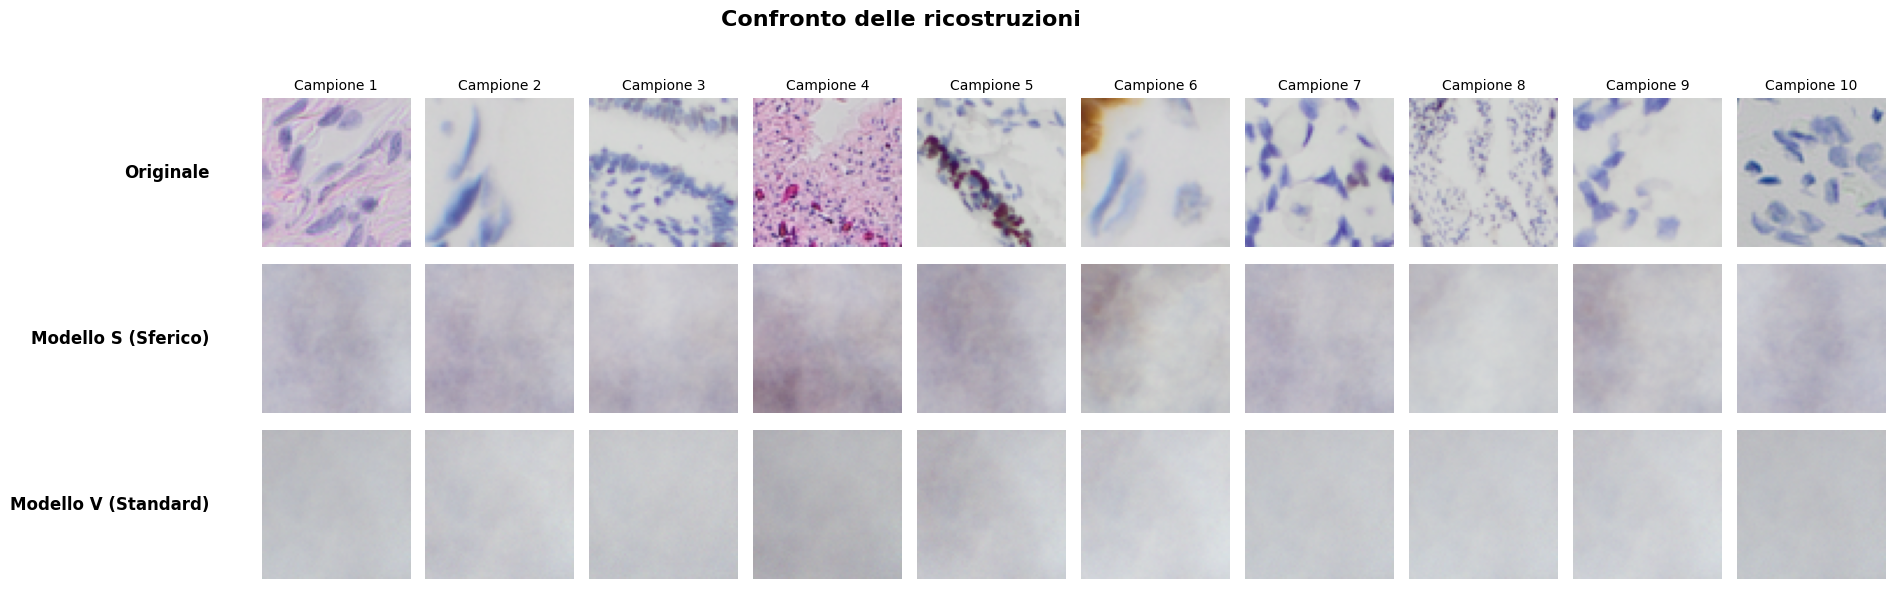

In [54]:
def visualizza_confronto_doppio(model_s, model_v, device, n_images=10):
    """
    Confronta le ricostruzioni di due modelli diversi.
    Riga 1: immagini originali
    Riga 2: ricostruzioni del modello sferico
    Riga 3: ricostruzioni del VAE standard
    """
    print("Generazione del confronto tra le ricostruzioni...")

    # Per CelebA il DataLoader restituisce direttamente un batch di immagini
    batch = next(iter(data_loader))
    data = batch.to(device)[:n_images]

    model_s.eval()
    model_v.eval()

    with torch.no_grad():
        recon_s, *rest = model_s(data)
        recon_v, *rest = model_v(data)

    data = data.cpu()

    if recon_s.ndim == 2:
        recon_s = recon_s.cpu().view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])
    else:
        recon_s = recon_s.cpu()

    if recon_v.ndim == 2:
        recon_v = recon_v.cpu().view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])
    else:
        recon_v = recon_v.cpu()

    n_show = data.size(0)
    fig, axes = plt.subplots(3, n_show, figsize=(2 * n_show, 6))

    if n_show == 1:
        axes = np.expand_dims(axes, axis=1)

    row_titles = ["Originale", "Modello S (Sferico)", "Modello V (Standard)"]

    for i in range(n_show):
        img_orig = data[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[0, i].imshow(img_orig)
        axes[0, i].axis("off")

        img_s = recon_s[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[1, i].imshow(img_s)
        axes[1, i].axis("off")

        img_v = recon_v[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[2, i].imshow(img_v)
        axes[2, i].axis("off")

        axes[0, i].set_title(f"Campione {i+1}", fontsize=10)

    for r in range(3):
        axes[r, 0].text(
            -0.35, 0.5, row_titles[r],
            transform=axes[r, 0].transAxes,
            fontsize=12,
            fontweight='bold',
            va='center',
            ha='right'
        )

    plt.suptitle("Confronto delle ricostruzioni", fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0.05, 0, 1, 0.95])
    plt.show()

visualizza_confronto_doppio(model_s, model_v, DEVICE, n_images=10)

Generazione di 10 nuove immagini da rumore casuale (Dim=32)...


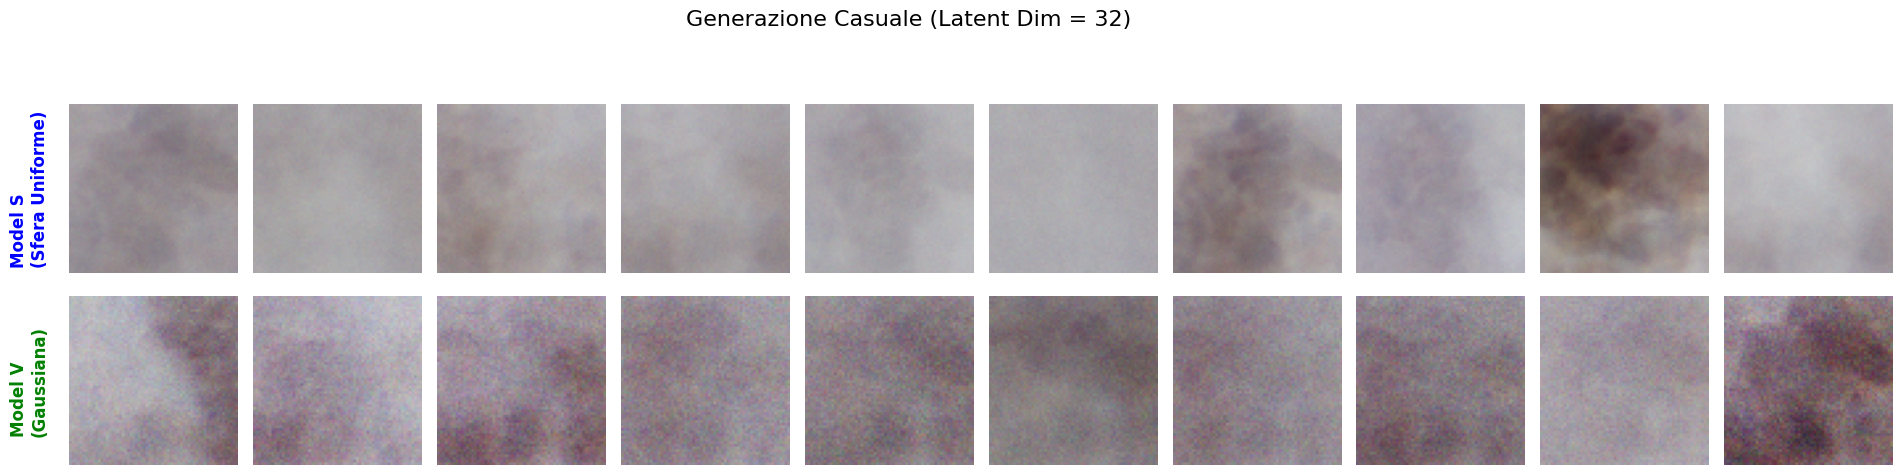

In [55]:
def visualizza_generazione_casuale(model_s, model_v, device, latent_dim, n_images=10):
    """
    Genera immagini da rumore casuale.
    - Model S: campionamento uniforme sulla sfera
    - Model V: campionamento gaussiano standard
    """
    print(f"Generazione di {n_images} nuove immagini da rumore casuale (Dim={latent_dim})...")

    model_s.eval()
    model_v.eval()

    # Campionamento latente
    z_s_raw = torch.randn(n_images, latent_dim).to(device)
    z_s = F.normalize(z_s_raw, p=2, dim=1)

    z_v = torch.randn(n_images, latent_dim).to(device)

    # Decodifica
    with torch.no_grad():
        gen_s = model_s.decode(z_s).cpu()
        gen_v = model_v.decode(z_v).cpu()

    # Se il decoder restituisce output flattenato, lo rimodella
    if gen_s.ndim == 2:
        gen_s = gen_s.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

    if gen_v.ndim == 2:
        gen_v = gen_v.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

    fig, axes = plt.subplots(2, n_images, figsize=(2 * n_images, 5))

    if n_images == 1:
        axes = np.expand_dims(axes, axis=1)

    for i in range(n_images):
        # Riga 1: modello sferico
        img_s = gen_s[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[0, i].imshow(img_s)
        axes[0, i].axis('off')

        # Riga 2: VAE standard
        img_v = gen_v[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[1, i].imshow(img_v)
        axes[1, i].axis('off')

    # Etichette a sinistra
    axes[0, 0].text(
        -0.35, 0.5, "Model S\n(Sfera Uniforme)",
        transform=axes[0, 0].transAxes,
        fontsize=12,
        rotation=90,
        verticalalignment='center',
        fontweight='bold',
        color='blue'
    )

    axes[1, 0].text(
        -0.35, 0.5, "Model V\n(Gaussiana)",
        transform=axes[1, 0].transAxes,
        fontsize=12,
        rotation=90,
        verticalalignment='center',
        fontweight='bold',
        color='green'
    )

    plt.suptitle(f"Generazione Casuale (Latent Dim = {latent_dim})", fontsize=16)
    plt.tight_layout(rect=[0.05, 0, 1, 0.93])
    plt.show()


visualizza_generazione_casuale(model_s, model_v, DEVICE, LATENT_DIM)

Estrazione vettori latenti dal dataset...
Calcolo PCA su 273 punti...


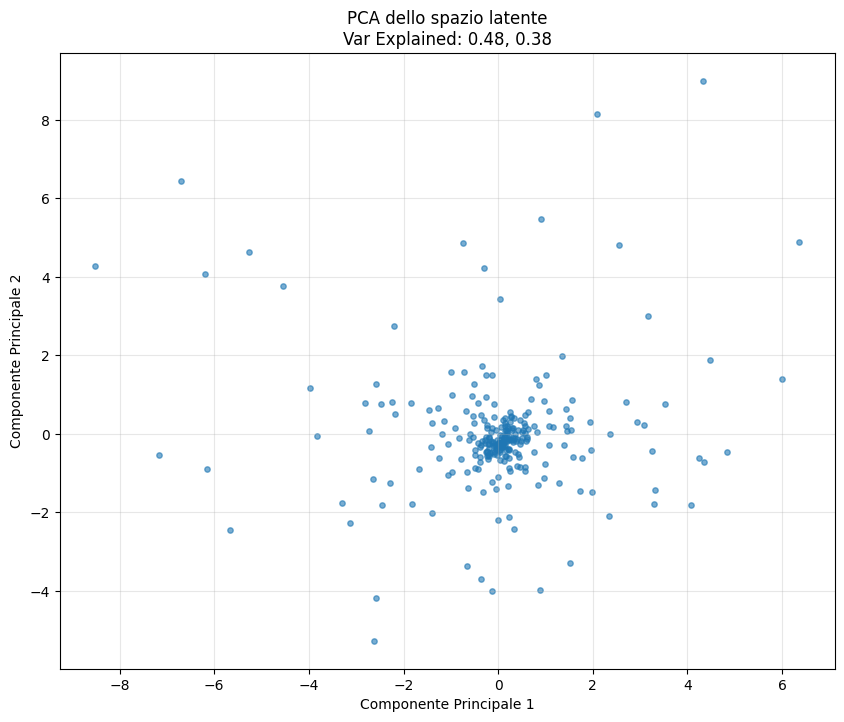

In [56]:
def visualizza_pca_training(model, device, num_points=5000):
    print("Estrazione vettori latenti dal dataset...")
    model.eval()

    loader = data_loader
    all_z = []
    count = 0

    with torch.no_grad():
        for batch in loader:
            # Per CelebA il loader restituisce direttamente le immagini
            if isinstance(batch, (list, tuple)):
                data = batch[0]
            else:
                data = batch

            data = data.to(device)

            # Se il modello è fully connected, fa il flatten
            # Se il modello è CNN, il controllo ndim dentro encode/forward gestirà il formato
            if hasattr(model, "fc1"):
                data_input = data.view(data.size(0), -1)
            else:
                data_input = data

            # encode può restituire (mu, logvar) oppure (mu, alpha)
            mu, *rest = model.encode(data_input)

            all_z.append(mu.cpu().numpy())

            count += data.size(0)
            if count >= num_points:
                break

    X = np.concatenate(all_z, axis=0)[:num_points]

    print(f"Calcolo PCA su {X.shape[0]} punti...")

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    plt.figure(figsize=(10, 8))
    plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6, s=15)

    var_ratio = pca.explained_variance_ratio_
    plt.title(f'PCA dello spazio latente\nVar Explained: {var_ratio[0]:.2f}, {var_ratio[1]:.2f}')
    plt.xlabel('Componente Principale 1')
    plt.ylabel('Componente Principale 2')
    plt.grid(True, alpha=0.3)
    plt.show()


visualizza_pca_training(model_v, DEVICE)

Confronto Interpolazione: SLERP (Sferico) vs LERP (VAE)...


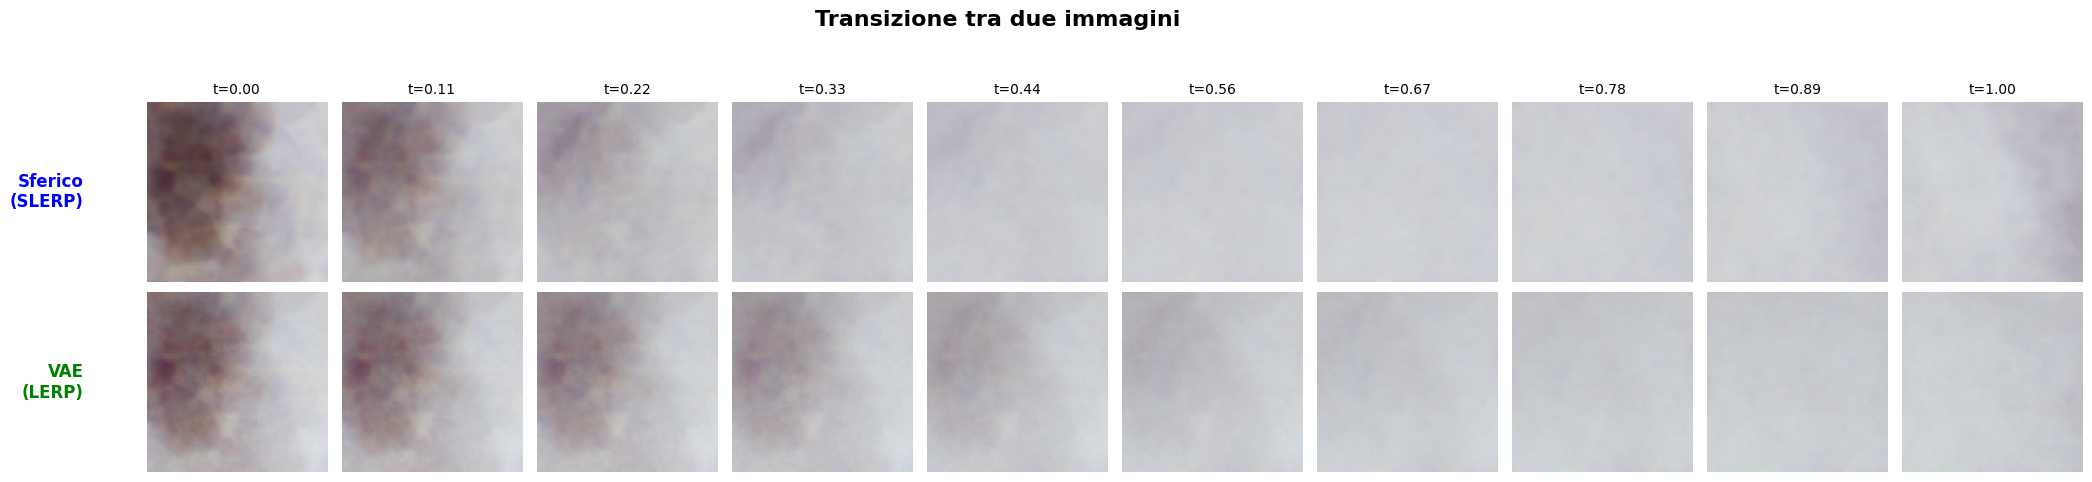

In [57]:

def slerp(val, low, high):
    """Interpolazione lineare sferica"""
    omega = torch.acos(
        torch.clamp(
            torch.sum(low / torch.norm(low) * high / torch.norm(high)),
            -1, 1
        )
    )
    so = torch.sin(omega)

    if so == 0:
        return (1.0 - val) * low + val * high

    return (
        torch.sin((1.0 - val) * omega) / so * low
        + torch.sin(val * omega) / so * high
    )

def lerp(val, low, high):
    """Interpolazione lineare standard"""
    return (1.0 - val) * low + val * high

def visualizza_interpolazione(model_s, model_v, device, steps=10):
    """
    Confronta l'interpolazione tra due immagini:
    - Modello sferico: SLERP
    - VAE standard: LERP
    """
    print("Confronto Interpolazione: SLERP (Sferico) vs LERP (VAE)...")

    loader = data_loader
    batch = next(iter(loader))

    # Per CelebA il loader restituisce direttamente immagini
    if isinstance(batch, (list, tuple)):
        images = batch[0]
    else:
        images = batch

    if images.size(0) < 2:
        raise ValueError("Il batch deve contenere almeno 2 immagini per l'interpolazione.")

    img1 = images[0].to(device)
    img2 = images[1].to(device)

    model_s.eval()
    model_v.eval()

    with torch.no_grad():
        # --- Encoding ---
        # Compatibilità con fully connected e CNN
        if img1.ndim == 3:
            img1_batch = img1.unsqueeze(0)
            img2_batch = img2.unsqueeze(0)
        else:
            img1_batch = img1
            img2_batch = img2

        # Se il modello è fully connected, fa il flatten
        if hasattr(model_s, "fc1"):
            z1_s = model_s.encode(img1_batch.view(-1, INPUT_DIM))[0]
            z2_s = model_s.encode(img2_batch.view(-1, INPUT_DIM))[0]
        else:
            z1_s = model_s.encode(img1_batch)[0]
            z2_s = model_s.encode(img2_batch)[0]

        if hasattr(model_v, "fc1"):
            z1_v = model_v.encode(img1_batch.view(-1, INPUT_DIM))[0]
            z2_v = model_v.encode(img2_batch.view(-1, INPUT_DIM))[0]
        else:
            z1_v = model_v.encode(img1_batch)[0]
            z2_v = model_v.encode(img2_batch)[0]

        ratios = np.linspace(0, 1, steps)
        pics_s = []
        pics_v = []

        for r in ratios:
            # Sferico -> SLERP
            z_interp_s = slerp(r, z1_s, z2_s)
            img_s = model_s.decode(z_interp_s).cpu()

            if img_s.ndim == 2:
                img_s = img_s.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

            pics_s.append(
                img_s[0].permute(1, 2, 0).clamp(0, 1).numpy()
            )

            # Standard VAE -> LERP
            z_interp_v = lerp(r, z1_v, z2_v)
            img_v = model_v.decode(z_interp_v).cpu()

            if img_v.ndim == 2:
                img_v = img_v.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

            pics_v.append(
                img_v[0].permute(1, 2, 0).clamp(0, 1).numpy()
            )

    fig, axes = plt.subplots(2, steps, figsize=(2.2 * steps, 5))

    if steps == 1:
        axes = np.expand_dims(axes, axis=1)

    for i in range(steps):
        axes[0, i].imshow(pics_s[i])
        axes[0, i].axis("off")

        axes[1, i].imshow(pics_v[i])
        axes[1, i].axis("off")

        axes[0, i].set_title(f"t={ratios[i]:.2f}", fontsize=10)

    axes[0, 0].text(
        -0.35, 0.5, "Sferico\n(SLERP)",
        transform=axes[0, 0].transAxes,
        fontsize=12,
        fontweight='bold',
        va='center',
        ha='right',
        color='blue'
    )

    axes[1, 0].text(
        -0.35, 0.5, "VAE\n(LERP)",
        transform=axes[1, 0].transAxes,
        fontsize=12,
        fontweight='bold',
        va='center',
        ha='right',
        color='green'
    )

    plt.suptitle("Transizione tra due immagini", fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0.05, 0, 1, 0.93])
    plt.show()

visualizza_interpolazione(model_s, model_v, DEVICE, steps=10)

Computing t-SNE with cosine metric...
Shape di X: (273, 32)
Dtype di X: float32


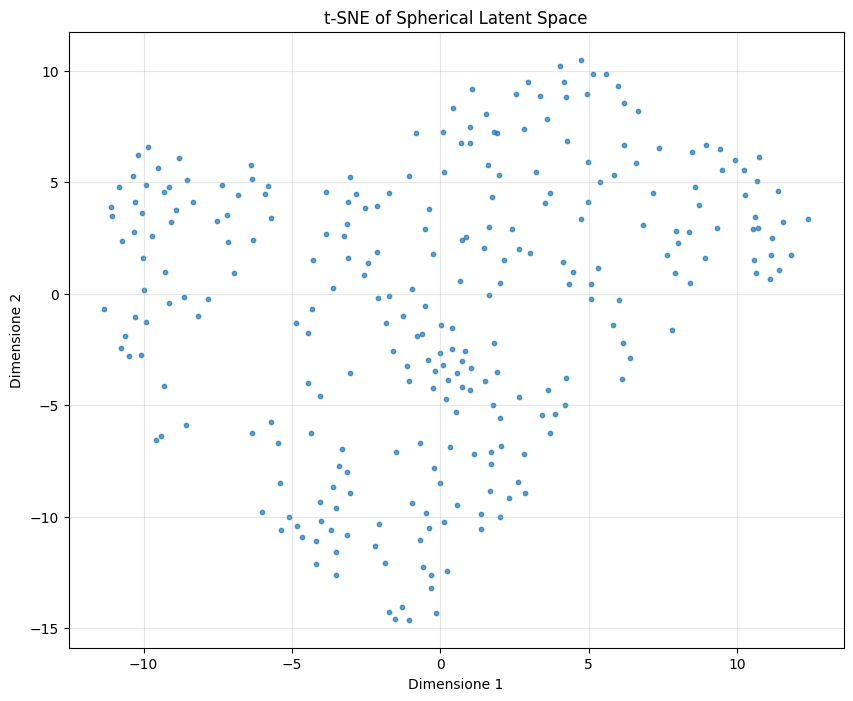

In [58]:

def visualizza_tsne_sferico(model, device, num_points=2000):
    """
    Visualizza il latent space con t-SNE.
    Versione per dataset senza label, come CelebA.
    """
    print("Computing t-SNE with cosine metric...")

    model.eval()
    loader = DataLoader(dataset, batch_size=128, shuffle=True)

    all_z = []
    count = 0

    with torch.no_grad():
        for batch in loader:
            if isinstance(batch, (list, tuple)):
                data = batch[0]
            else:
                data = batch

            data = data.to(device)

            if hasattr(model, "fc1"):
                data_input = data.view(data.size(0), -1)
            else:
                data_input = data

            z, *rest = model.encode(data_input)

            z_np = z.detach().cpu().numpy().astype(np.float32)
            all_z.append(z_np)

            count += data.size(0)
            if count >= num_points:
                break

    X = np.concatenate(all_z, axis=0)[:num_points].astype(np.float32)

    print("Shape di X:", X.shape)
    print("Dtype di X:", X.dtype)

    tsne = TSNE(
        n_components=2,
        metric='cosine',
        init='pca',
        learning_rate=200,   # qui era 'auto'
        random_state=42
    )

    X_embedded = tsne.fit_transform(X)

    plt.figure(figsize=(10, 8))
    plt.scatter(X_embedded[:, 0], X_embedded[:, 1], s=10, alpha=0.7)
    plt.title("t-SNE of Spherical Latent Space")
    plt.xlabel("Dimensione 1")
    plt.ylabel("Dimensione 2")
    plt.grid(True, alpha=0.3)
    plt.show()

visualizza_tsne_sferico(model_s, DEVICE, 2000)


--- Diversity analysis on 1000 generated samples ---
Real dataset diversity: 17.5450
Spherical diversity: 11.3491
Standard diversity:  12.7302
----------------------------------------
Spherical: 64.7% of real diversity
Standard : 72.6% of real diversity
----------------------------------------


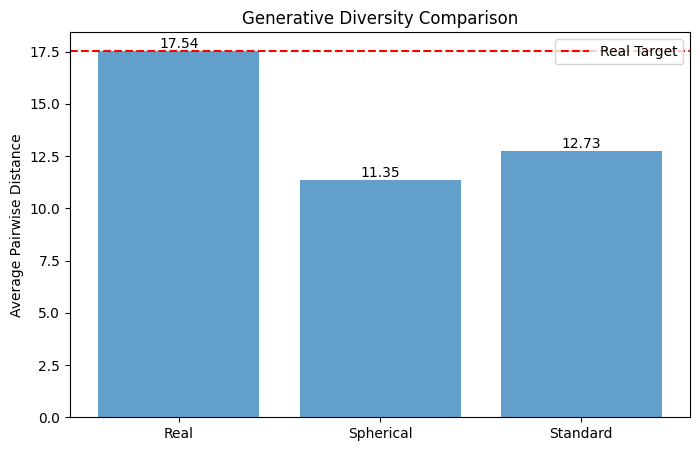

In [59]:

# Diversity statistics
def get_average_pairwise_distance(images_tensor):
    """
    Calcola la distanza euclidea media tra tutte le coppie di immagini.
    """
    flat = images_tensor.view(images_tensor.size(0), -1)
    dists = torch.cdist(flat, flat, p=2)
    return dists.mean().item()


def confronto_diversita(model_g, model_v, device, latent_dim, n_samples=1000):
    """
    Confronta la diversità tra:
    - immagini reali
    - immagini generate dal modello sferico
    - immagini generate dal VAE standard

    Compatibile con dataset con o senza label.
    Compatibile con decoder che restituiscono output flattenato
    o immagini già in formato [B, C, H, W].
    """
    print(f"\n--- Diversity analysis on {n_samples} generated samples ---")

    model_g.eval()
    model_v.eval()

    # Estrazione immagini reali
    real_loader = DataLoader(dataset, batch_size=n_samples, shuffle=True)
    batch = next(iter(real_loader))

    # Se il dataset restituisce (data, label), prende solo le immagini
    if isinstance(batch, (list, tuple)):
        real_imgs = batch[0]
    else:
        real_imgs = batch

    # Se arriva una singola immagine, aggiunge batch dimension
    if real_imgs.ndim == 3:
        real_imgs = real_imgs.unsqueeze(0)

    real_imgs = real_imgs[:n_samples].to(device)

    diversity_real = get_average_pairwise_distance(real_imgs)
    print(f"Real dataset diversity: {diversity_real:.4f}")

    with torch.no_grad():
        # Campionamento sferico
        z_g = torch.randn(n_samples, latent_dim).to(device)
        z_g = F.normalize(z_g, p=2, dim=1)
        gen_imgs_g = model_g.decode(z_g)

        # Campionamento standard
        z_v = torch.randn(n_samples, latent_dim).to(device)
        gen_imgs_v = model_v.decode(z_v)

        # Se il decoder restituisce output flattenato, lo rimodella
        if gen_imgs_g.ndim == 2:
            gen_imgs_g = gen_imgs_g.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

        if gen_imgs_v.ndim == 2:
            gen_imgs_v = gen_imgs_v.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

        diversity_g = get_average_pairwise_distance(gen_imgs_g)
        diversity_v = get_average_pairwise_distance(gen_imgs_v)

    print(f"Spherical diversity: {diversity_g:.4f}")
    print(f"Standard diversity:  {diversity_v:.4f}")

    perc_g = (diversity_g / diversity_real) * 100
    perc_v = (diversity_v / diversity_real) * 100

    print("-" * 40)
    print(f"Spherical: {perc_g:.1f}% of real diversity")
    print(f"Standard : {perc_v:.1f}% of real diversity")
    print("-" * 40)

    plt.figure(figsize=(8, 5))
    methods = ['Real', 'Spherical', 'Standard']
    values = [diversity_real, diversity_g, diversity_v]

    bars = plt.bar(methods, values, alpha=0.7)
    plt.axhline(y=diversity_real, color='red', linestyle='--', label='Real Target')

    plt.ylabel("Average Pairwise Distance")
    plt.title("Generative Diversity Comparison")
    plt.legend()

    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            yval,
            f"{yval:.2f}",
            ha='center',
            va='bottom'
        )

    plt.show()


confronto_diversita(model_s, model_v, DEVICE, LATENT_DIM)


--- FID su 2000 campioni generati  ---

Calcolo FID per il modello sferico...
Estrazione di 2000 immagini reali...
Generazione di 2000 immagini sintetiche...
Estrazione feature Inception per immagini reali...
Estrazione feature Inception per immagini generate...

Calcolo FID per il VAE standard...
Estrazione di 2000 immagini reali...
Generazione di 2000 immagini sintetiche...
Estrazione feature Inception per immagini reali...
Estrazione feature Inception per immagini generate...
----------------------------------------
FID Modello Sferico : 319.0249
FID VAE Standard    : 266.0268
----------------------------------------
Nota: un valore FID più basso indica una migliore qualità generativa.


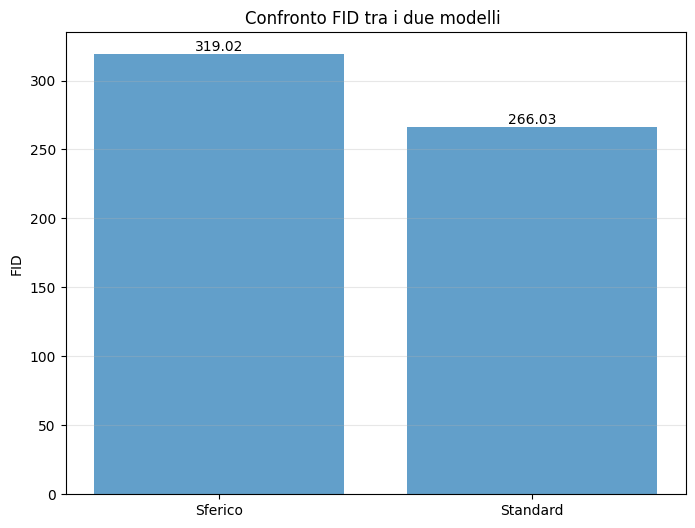

In [62]:
from torchvision.models import inception_v3
from scipy.linalg import sqrtm

class InceptionFeatureExtractor(nn.Module):
    """
    Estrae feature da InceptionV3 pre-addestrata.
    Compatibile con versioni meno recenti di torchvision.
    """
    def __init__(self, device):
        super().__init__()
        self.model = inception_v3(weights=True, transform_input=False)
        self.model.fc = nn.Identity()
        self.model.eval()
        self.model.to(device)

    def forward(self, x):
        if x.shape[1] == 1:
            x = x.repeat(1, 3, 1, 1)

        x = F.interpolate(x, size=(299, 299), mode='bilinear', align_corners=False)

        mean = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1)
        x = (x - mean) / std

        with torch.no_grad():
            feat = self.model(x)

        return feat


def get_real_images_from_loader(loader, n_samples, device):
    imgs = []
    collected = 0

    for batch in loader:
        if isinstance(batch, (list, tuple)):
            data = batch[0]
        else:
            data = batch

        imgs.append(data)
        collected += data.size(0)

        if collected >= n_samples:
            break

    imgs = torch.cat(imgs, dim=0)[:n_samples].to(device)
    return imgs


def get_generated_images(model, latent_dim, n_samples, device):
    model.eval()

    with torch.no_grad():
        model_name = model.__class__.__name__.lower()

        if "spherical" in model_name or "geodesic" in model_name:
            z = torch.randn(n_samples, latent_dim, device=device)
            z = F.normalize(z, p=2, dim=1)
        else:
            z = torch.randn(n_samples, latent_dim, device=device)

        imgs = model.decode(z)

        if imgs.ndim == 2:
            imgs = imgs.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

        imgs = imgs.clamp(0, 1)

    return imgs


def get_activations(images, feature_extractor, batch_size=64):
    acts = []

    for i in range(0, images.size(0), batch_size):
        batch = images[i:i + batch_size]
        feat = feature_extractor(batch)
        acts.append(feat.cpu().numpy())

    acts = np.concatenate(acts, axis=0).astype(np.float64)
    return acts


def compute_statistics(activations):
    mu = np.mean(activations, axis=0)
    sigma = np.cov(activations, rowvar=False)
    return mu, sigma


def calculate_fid(mu1, sigma1, mu2, sigma2, eps=1e-6):
    diff = mu1 - mu2

    covmean = sqrtm(sigma1 @ sigma2)

    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = sqrtm((sigma1 + offset) @ (sigma2 + offset))

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = diff @ diff + np.trace(sigma1 + sigma2 - 2 * covmean)
    return float(fid)


def compute_fid_for_model(model, real_loader, latent_dim, n_samples, device, feature_extractor):
    print(f"Estrazione di {n_samples} immagini reali...")
    real_imgs = get_real_images_from_loader(real_loader, n_samples, device)

    print(f"Generazione di {n_samples} immagini sintetiche...")
    fake_imgs = get_generated_images(model, latent_dim, n_samples, device)

    print("Estrazione feature Inception per immagini reali...")
    real_acts = get_activations(real_imgs, feature_extractor)

    print("Estrazione feature Inception per immagini generate...")
    fake_acts = get_activations(fake_imgs, feature_extractor)

    mu_real, sigma_real = compute_statistics(real_acts)
    mu_fake, sigma_fake = compute_statistics(fake_acts)

    fid = calculate_fid(mu_real, sigma_real, mu_fake, sigma_fake)
    return fid


def confronta_fid_celeba(model_s, model_v, real_loader, latent_dim, device, n_samples=2000):
    print(f"\n--- FID su {n_samples} campioni generati  ---")

    feature_extractor = InceptionFeatureExtractor(device)

    print("\nCalcolo FID per il modello sferico...")
    fid_s = compute_fid_for_model(
        model=model_s,
        real_loader=real_loader,
        latent_dim=latent_dim,
        n_samples=n_samples,
        device=device,
        feature_extractor=feature_extractor
    )

    print("\nCalcolo FID per il VAE standard...")
    fid_v = compute_fid_for_model(
        model=model_v,
        real_loader=real_loader,
        latent_dim=latent_dim,
        n_samples=n_samples,
        device=device,
        feature_extractor=feature_extractor
    )

    print("-" * 40)
    print(f"FID Modello Sferico : {fid_s:.4f}")
    print(f"FID VAE Standard    : {fid_v:.4f}")
    print("-" * 40)
    print("Nota: un valore FID più basso indica una migliore qualità generativa.")

    labels = ["Sferico", "Standard"]
    values = [fid_s, fid_v]

    plt.figure(figsize=(8, 6))
    bars = plt.bar(labels, values, alpha=0.7)
    plt.ylabel("FID")
    plt.title("Confronto FID tra i due modelli ")
    plt.grid(axis="y", alpha=0.3)

    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            yval,
            f"{yval:.2f}",
            ha="center",
            va="bottom"
        )

    plt.show()

    return fid_s, fid_v


fid_s, fid_v = confronta_fid_celeba(
    model_s,
    model_v,
    data_loader,
    LATENT_DIM,
    DEVICE,
    n_samples=2000
)